# TP 2 Extraction d'informations

## Imports et stopwords

In [67]:
import os
import yake
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/alexiawaucquez/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Choix d'une année

In [2]:
# Choisir une année
year = 1969

In [13]:
# Lister les fichiers de cette année
data_path = './txt'
txt_path = './txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [9]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [10]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = './tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

## Extraction de mots clefs

In [68]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [69]:
# Lister les Fichiers
data_path = "./tmp"
files = [f for f in os.listdir(data_path) if f.endswith('.txt')]

In [15]:
for f in sorted(files):
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

1969.txt mentions these keywords: Agence Rossel, Bruxelles Tél, l’Agence Rossel, Bruxelles dem, BRUXELLES DEMANDE, BRUXELLES engage, Bar dem, Dames dem, BRUXELLES CENTRE, Ecrire Agence, bel app, Bruxelles Bruxelles, Faire offre, rue Royale...


## Enrichissement de la liste de stopwords et génération du nuage de mots

In [88]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", "l", "tel", "tél", 
       "écrire", "etc", "ets", "app", "très", "trav", "sdb", "brux", "gar","prés", 
       "bur", "bxl", "chb", "dès", "toute", "chff", "frs", "cft", "fem", "faç", "rens",
       "déjà", "poss", "jne", "maz", "mat", "ecr", "imm", "leurs", "hres", "emp", "pet"]
sw = set(sw)


In [89]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [90]:
clean_text(year, folder=temp_path)

'Output has been written in ./tmp/1969_clean.txt!'

In [91]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'VANDEN BOUDE CHAUSSÉE MONS ANDERLECTIT BRUXELLES DEMANDENT ELECTRICIENS QUALIFIES INSTALLATION BASSE TENSION PLOMBIERS SACHANT CONDUIRE POSSIBLE MAGASINIERS DÉPÔT RUE ROUE PLACE STABLE AVENIR FIRME CONTINUELLE EXPANSION BONNE RÉMUNÉRATION PRIÈRE ADRESSER SERVICE PERSONNEL DOCT ZAMENHOF ANDERLECHT VEEWEYDE POSTE AUTOBUS TRAMS VANDERBORGHT FRÈRES ENGAGENT AIDES MAGASINIERS PRÉPARATION COMMANDES BONS SALAIRES SEMAINES JOURS PENSION EXTRA LÉGALE GRATUITE PRÉSENTER SERVICE PERSONNEL RUE FOSSÉ LOUPS B'

In [92]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('BRUXELLES', 1395), ('RUE', 1168), ('ANS', 637), ('HEURES', 486), ('CUIS', 465), ('PRIX', 451), ('ECRIRE', 434), ('DEMANDE', 413), ('PART', 399), ('SOIR', 395)]


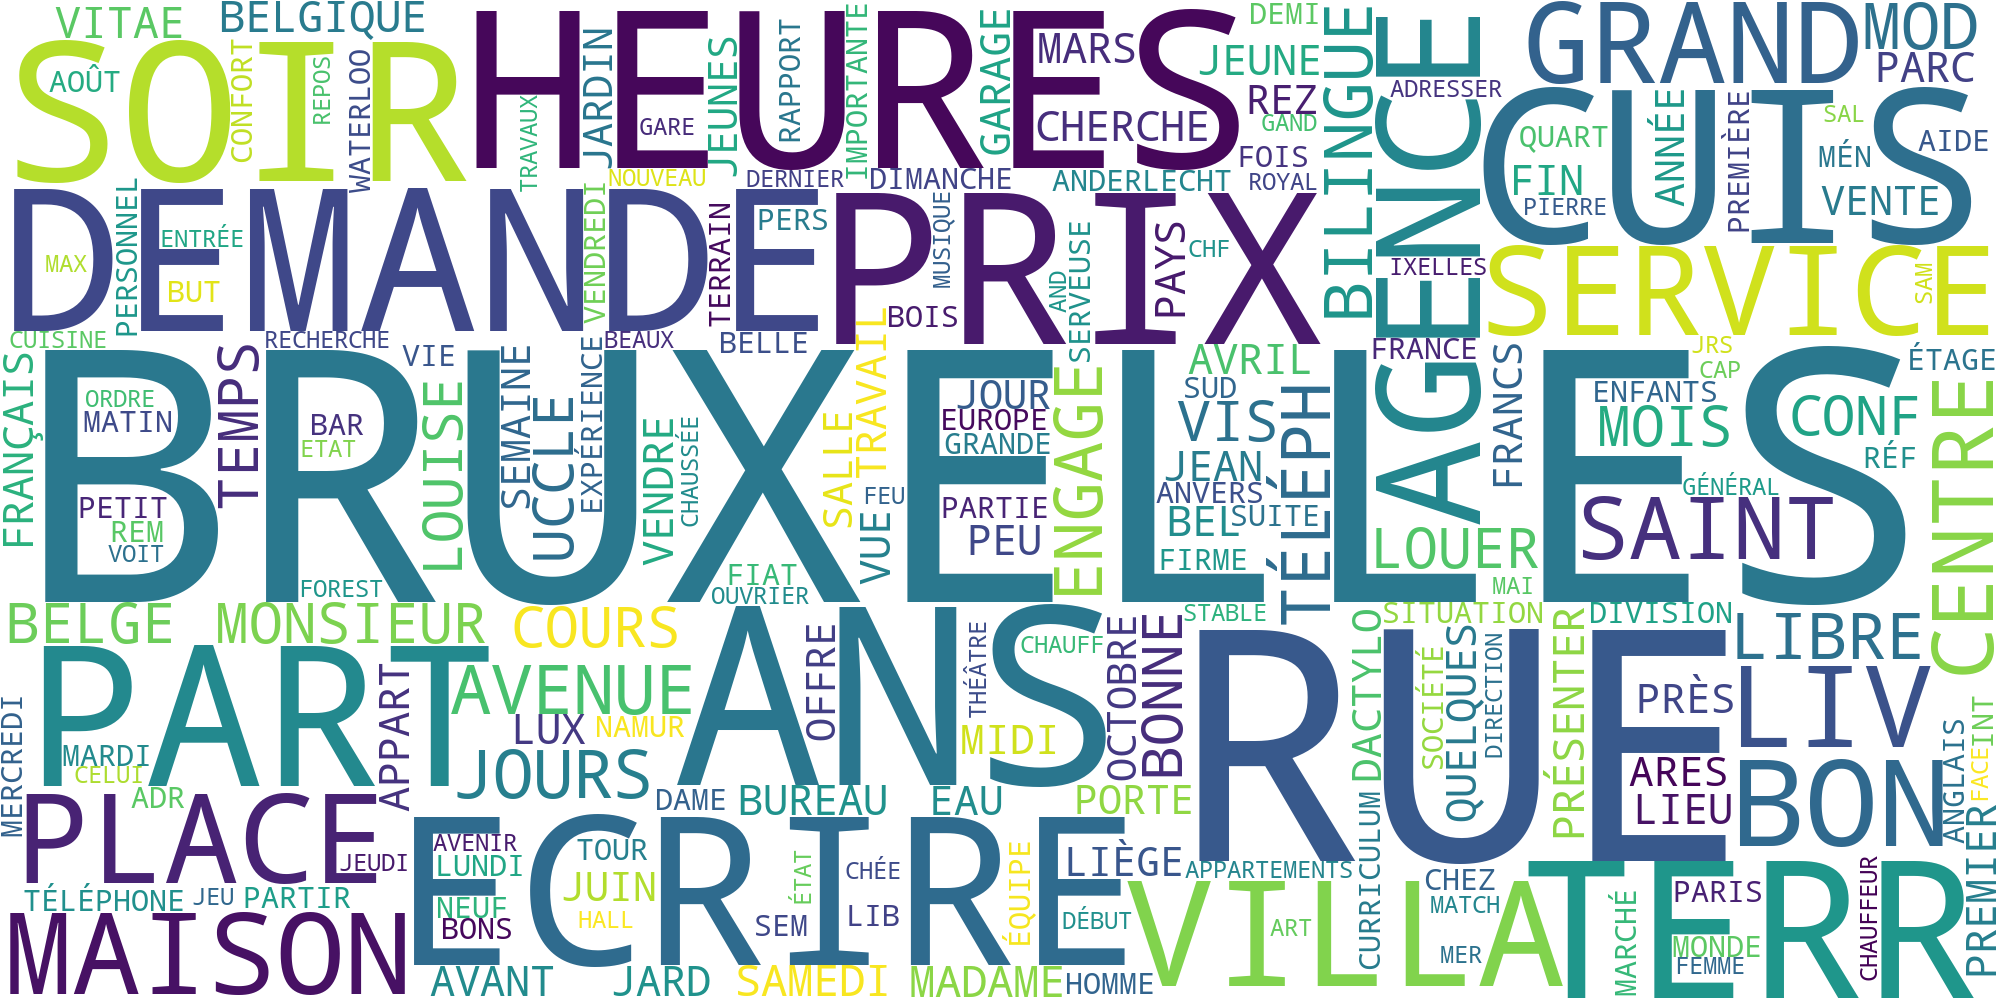

In [93]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## Entités principales pertinentes

In [31]:
nlp = spacy.load('fr_core_news_md')

In [48]:
# Charger le texte
n=1000000
text = open("./tmp/1969.txt", encoding='utf-8').read()[:n]

In [49]:
%%time
# Traiter le texte

doc = nlp(text)

CPU times: user 45 s, sys: 8.86 s, total: 53.9 s
Wall time: 1min 5s


In [50]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1

In [51]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 80 fois dans le corpus
- Tél apparait 43 fois dans le corpus
Louise apparait 34 fois dans le corpus
Jeremy apparait 26 fois dans le corpus
Monsieur apparait 23 fois dans le corpus
Paula apparait 22 fois dans le corpus
Martin apparait 17 fois dans le corpus
Ecrire Ag apparait 16 fois dans le corpus
trav apparait 15 fois dans le corpus
curr apparait 15 fois dans le corpus
F. Tél apparait 13 fois dans le corpus
entret apparait 12 fois dans le corpus
tt cft apparait 12 fois dans le corpus
s.d.b apparait 12 fois dans le corpus
F. T. apparait 12 fois dans le corpus
Van Himst apparait 12 fois dans le corpus
atel apparait 10 fois dans le corpus
Agence Rossel apparait 9 fois dans le corpus
A.F.P. apparait 9 fois dans le corpus
Eddy Merckx apparait 9 fois dans le corpus
Dewalque apparait 9 fois dans le corpus
Van Volxem apparait 8 fois dans le corpus
MONSIEUR apparait 8 fois dans le corpus
pr trav apparait 7 fois dans le corpus
Robert Stolz apparait 7 fois dans le corpus
Aldrin a

In [52]:
# Compter les entités loc
localities = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "LOC" and len(ent.text) > 3:
        localities[ent.text] += 1

In [53]:
# Trier et imprimer

sorted_localities = sorted(localities.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_localities[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Bruxelles apparait 172 fois dans le corpus
Brux apparait 151 fois dans le corpus
Téléph apparait 63 fois dans le corpus
Belgique apparait 48 fois dans le corpus
Liège apparait 35 fois dans le corpus
Lune apparait 32 fois dans le corpus
Uccle apparait 30 fois dans le corpus
chff apparait 30 fois dans le corpus
Anderlecht apparait 28 fois dans le corpus
s.d.b apparait 28 fois dans le corpus
Anvers apparait 27 fois dans le corpus
Jumelé apparait 26 fois dans le corpus
Gand apparait 24 fois dans le corpus
Paris apparait 24 fois dans le corpus
Londres apparait 23 fois dans le corpus
Schaerbeek apparait 22 fois dans le corpus
Europe apparait 22 fois dans le corpus
Etats-Unis apparait 21 fois dans le corpus
Bruxelles 1 apparait 19 fois dans le corpus
Bruxelles 5 apparait 19 fois dans le corpus
terr apparait 19 fois dans le corpus
Forest apparait 18 fois dans le corpus
Agence Rossel apparait 17 fois dans le corpus
Namur apparait 17 fois dans le corpus
Ixelles apparait 17 fois dans le corpus
Ro

In [54]:
# Compter les entités org
organisations = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "ORG" and len(ent.text) > 3:
        organisations[ent.text] += 1

In [55]:
# Trier et imprimer

sorted_organisations = sorted(organisations.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_organisations[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Standard apparait 29 fois dans le corpus
Agence Rossel apparait 16 fois dans le corpus
SNCB apparait 15 fois dans le corpus
Téléphone apparait 12 fois dans le corpus
Conseil d’Etat apparait 12 fois dans le corpus
Conseil apparait 10 fois dans le corpus
ELECTRICIENS apparait 9 fois dans le corpus
MANŒUVRES apparait 9 fois dans le corpus
trav apparait 9 fois dans le corpus
Coiff apparait 9 fois dans le corpus
PARC apparait 9 fois dans le corpus
EMPLOYEE apparait 8 fois dans le corpus
Fiat apparait 8 fois dans le corpus
fiat apparait 8 fois dans le corpus
Mutuel apparait 8 fois dans le corpus
La Direction apparait 8 fois dans le corpus
FIRME apparait 8 fois dans le corpus
Real Madrid apparait 8 fois dans le corpus
Service du Personnel apparait 7 fois dans le corpus
Chevalier apparait 7 fois dans le corpus
Royal Dutch apparait 6 fois dans le corpus
Racing-White apparait 6 fois dans le corpus
EVERE apparait 5 fois dans le corpus
pacte de Varsovie apparait 5 fois dans le corpus
Constitution 

## Analyse de sentiments

In [56]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

In [57]:
#1 5 Janvier
get_sentiment("L'activité est moins étoffée que la Veille et quelques prises de bénéfices donnent à la cote une physionomie moins uniformément favorable.")

This text is 50% positive and 60% subjective.


In [58]:
#2 9 Février
get_sentiment("L’œuvre que Verdi écrivit voici un siècle n’a rien perdu de sa faveur auprès du public.")

This text is 11% positive and 20% subjective.


In [59]:
#3 1er Mars
get_sentiment("Un investissement judicieux dans une commune résidentielle, que vous décidiez d'y résider, de le louer, ou que vous envisagiez de le revendre un jour, votre appartement au Domaine du Wotvenberg possédera une série d'avantages particulièrement appréciables.")

This text is 8% positive and 10% subjective.


In [60]:
#4 27 Avril
get_sentiment("Au risque de jeter un trouble dans l’atmosphère allègre qui règne à nouveau au parc Astrid, nous poserons tout de même la question de savoir si tout eût été aussi facile devant une opposition plus redoutable que celle-ci.")

This text is 11% positive and 33% subjective.


In [61]:
#5 22 Mai
get_sentiment("Vous avez un esprit pratique qui a le sens du solide.")

This text is 35% positive and 25% subjective.


In [62]:
#6 26 Juin
get_sentiment("On nous prie d'annoncer le décès de MADAME Henri MAHIEU, née Octavie DE WAELE, survenu à Ixelles le 21 juin 1969 dans sa 71 année.")

This text is neutral and perfectly objective.


In [63]:
#7 20,21,22 Juillet
get_sentiment("Au moment où le module se posait sur la Lune, le « Hornet », navire chargé de récupérer les cosmonautes, faisait route dans le Pacifique équatorial, vers une région de cet océan dont la carte sous-marine n’a pas encore été établie.")

This text is 40% positive and 80% subjective.


In [64]:
#8 11 Septembre
get_sentiment("C’est au cours de la première manche des épreuves derrière vélomoteurs qui opposaient Eddy Merckx, Anquetil, Riotte, Graczyck, Perin et Daler que se produisait une chute fantastique.")

This text is 75% positive and 60% subjective.


In [65]:
#9 24 octobre
get_sentiment("M. Lefèvre parle ensuite de l’intégration du marché, et montre comment, sans pareille unité, la concentration industrielle et le succès économique américain n’auraient pas vu le jour si chaque Etat américain avait gardé sa pleine autonomie, ou si le gouvernement fédéral était resté faible, comme il l’était à ses débuts.")

This text is 4% positive and 22% subjective.


In [66]:
#10 17 Décembre
get_sentiment("Lorsque les études terminées sont des études du cycle secondaire supérieur, pour pouvoir prétendre aux allocations de chômage, le jeune travailleur doit justifier de septante- cinq journées d’inscription comme demandeur d’emploi ou de travail salarié, dans l’année de la fin de ces études.")

This text is 21% positive and 32% subjective.
